In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("../data/OnlineRetail.xlsx")

print(df.shape)
display(df.head())
df.info()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,554065,22755,SMALL PURPLE BABUSHKA NOTEBOOK,12,2011-05-22 10:39:00,0.85,18287.0,United Kingdom
1,554065,22754,SMALL RED BABUSHKA NOTEBOOK,12,2011-05-22 10:39:00,0.85,18287.0,United Kingdom
2,554065,22753,SMALL YELLOW BABUSHKA NOTEBOOK,12,2011-05-22 10:39:00,0.85,18287.0,United Kingdom
3,554065,22756,LARGE YELLOW BABUSHKA NOTEBOOK,12,2011-05-22 10:39:00,1.25,18287.0,United Kingdom
4,554065,22758,LARGE PURPLE BABUSHKA NOTEBOOK,12,2011-05-22 10:39:00,1.25,18287.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [22]:

df = df.drop_duplicates()


df = df.dropna(subset=["CustomerID"])


df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()


df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

print("Dimensions après nettoyage :", df.shape)
print("Valeurs manquantes :", df.isna().sum().sum())

Dimensions après nettoyage : (392692, 8)
Valeurs manquantes : 0


In [23]:

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]


date_reference = df["InvoiceDate"].max() + pd.Timedelta(days=1)


rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (date_reference - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

display(rfm.head())
print("Nombre de clients :", rfm.shape[0])

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


Nombre de clients : 4338


In [24]:
from sklearn.preprocessing import StandardScaler

features = ["Recency", "Frequency", "Monetary"]

rfm_log = rfm.copy()
rfm_log[features] = np.log1p(rfm_log[features])

scaler = StandardScaler()
X = scaler.fit_transform(rfm_log[features])

print("Dimensions de X :", X.shape)
print("Moyennes :", X.mean(axis=0))
print("Écarts-types :", X.std(axis=0))


Dimensions de X : (4338, 3)
Moyennes : [-8.02595529e-17 -8.18975030e-18 -3.66900813e-16]
Écarts-types : [1. 1. 1.]


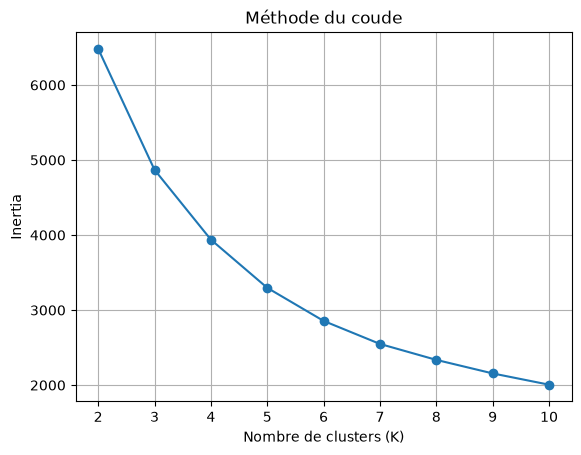

In [25]:
from sklearn.cluster import KMeans

inertias = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X)
    inertias.append(model.inertia_)

plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertia")
plt.title("Méthode du coude")
plt.grid(True)
plt.show()

In [26]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10)
    labels = model.fit_predict(X)

    score = silhouette_score(
        X,
        labels,
        sample_size=2000,
        random_state=42
    )
    silhouette_scores.append(score)

    print(f"K = {k} | Silhouette Score = {score:.3f}")

K = 2 | Silhouette Score = 0.426
K = 3 | Silhouette Score = 0.328
K = 4 | Silhouette Score = 0.333
K = 5 | Silhouette Score = 0.318
K = 6 | Silhouette Score = 0.317
K = 7 | Silhouette Score = 0.310
K = 8 | Silhouette Score = 0.302
K = 9 | Silhouette Score = 0.278
K = 10 | Silhouette Score = 0.277


In [27]:
kmeans = KMeans (
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X)

print(rfm["Cluster"].value_counts().sort_index())


Cluster
0     769
1    1872
2    1697
Name: count, dtype: int64


In [28]:
rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,17.06,13.35,7898.46
1,167.36,1.35,361.00
2,44.20,3.38,1259.58


In [29]:
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,2
1,12347.0,2,7,4310.00,0
2,12348.0,75,4,1797.24,2
3,12349.0,19,1,1757.55,2
4,12350.0,310,1,334.40,1


In [30]:
profil = rfm.groupby("Cluster").agg(
    Nombre_clients=("CustomerID", "count"),
    Chiffre_affaires=("Monetary", "sum")
)

profil["Contribution_CA_%"] = (profil["Chiffre_affaires"] / profil["Chiffre_affaires"].sum() * 100).round(2)

display(profil.round(2))

,Nombre_clients,Chiffre_affaires,Contribution_CA_%
Cluster,,,
0,769,6073917.28,68.34
1,1872,675785.35,7.60
2,1697,2137506.26,24.05


In [31]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

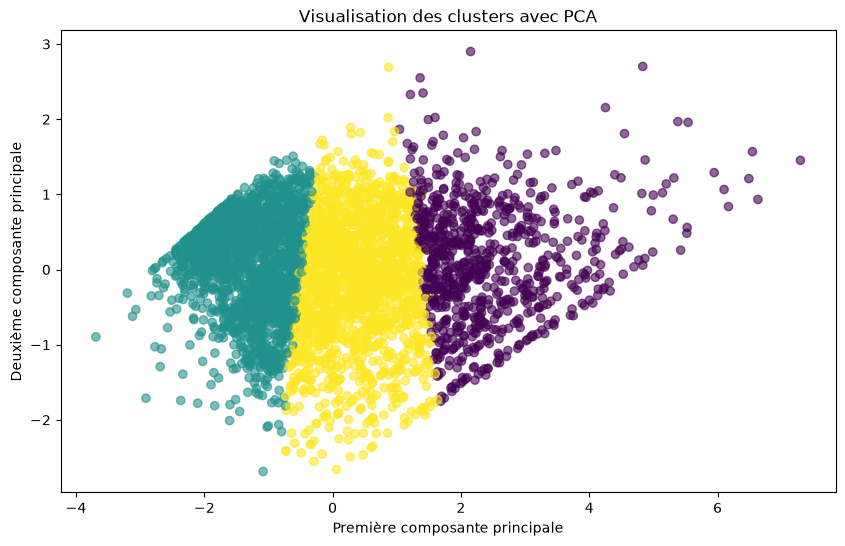

In [32]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=rfm["Cluster"],
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("Première composante principale")
plt.ylabel("Deuxième composante principale")
plt.title("Visualisation des clusters avec PCA")
plt.show()

In [33]:
from sklearn.model_selection import train_test_split

features = ["Recency", "Frequency", "Monetary"]

X_rf = rfm[features]
y_rf = rfm["Cluster"]

X_train, X_test, y_train, y_test = train_test_split(
    X_rf,
    y_rf,
    test_size=0.2,
    random_state=42,
    stratify=y_rf
)

In [34]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

In [35]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

Accuracy : 0.9804147465437788


In [36]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[148   0   6]
 [  0 370   5]
 [  1   5 333]]


In [37]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

cv_mean = cv_scores.mean()

print("Accuracy moyenne :", cv_mean)
print("Accuracy :", cv_scores)


Accuracy moyenne : 0.9804034582132564
Accuracy : [0.98270893 0.98559078 0.97838617 0.97982709 0.97550432]


In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Precision :", precision)
print("Recall :", recall)
print("F1-score :", f1)

Precision : 0.9805602841865787
Recall : 0.9804147465437788
F1-score : 0.9804198959680464


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ==========================================
# 1. Accuracy
# ==========================================

accuracy = accuracy_score(y_test, y_pred)


# ==========================================
# 2. Precision
# ==========================================

precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)


# ==========================================
# 3. Recall
# ==========================================

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)


# ==========================================
# 4. F1-score
# ==========================================

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)


# ==========================================
# 5. Matrice de confusion
# ==========================================

cm = confusion_matrix(
    y_test,
    y_pred
)


# ==========================================
# Affichage des résultats
# ==========================================

print("========== ÉVALUATION DU MODÈLE ==========")

print("Accuracy  :", accuracy)
print("Precision :", precision)
print("Recall    :", recall)
print("F1-score  :", f1)

print("\nMatrice de confusion :")
print(cm)

========== ÉVALUATION DU MODÈLE ==========
Accuracy  : 0.9804147465437788
Precision : 0.9805602841865787
Recall    : 0.9804147465437788
F1-score  : 0.9804198959680464

Matrice de confusion :
[[148   0   6]
 [  0 370   5]
 [  1   5 333]]


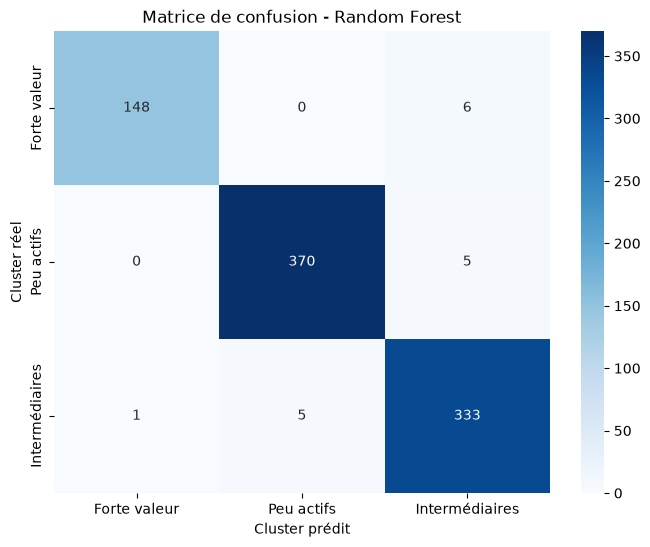

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Noms des clusters
cluster_names = [
    "Forte valeur",
    "Peu actifs",
    "Intermédiaires"
]

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

# Affichage
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cluster_names,
    yticklabels=cluster_names
)

plt.xlabel("Cluster prédit")
plt.ylabel("Cluster réel")
plt.title("Matrice de confusion - Random Forest")

plt.show()

In [42]:
feature_importance = rf_model.feature_importances_

print(feature_importance)
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

[0.31637311 0.35235363 0.33127326]
     Feature  Importance
1  Frequency    0.352354
2   Monetary    0.331273
0    Recency    0.316373


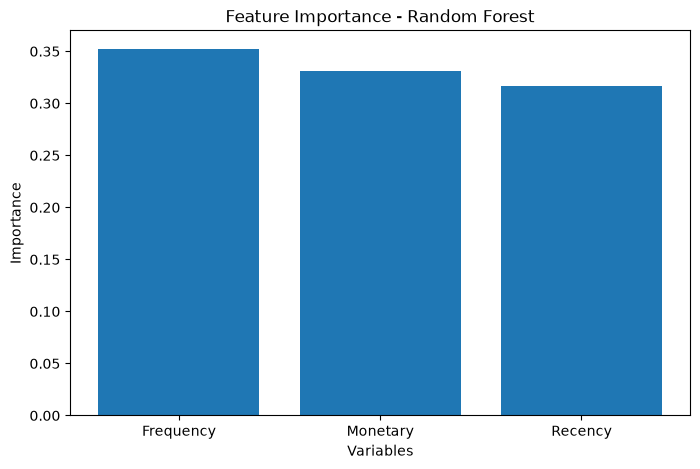

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Variables")
plt.ylabel("Importance")
plt.title("Feature Importance - Random Forest")

plt.show()


In [45]:
new_client = pd.DataFrame({
    "Recency": [20],
    "Frequency": [10],
    "Monetary": [5000]
})

predicted_cluster = rf_model.predict(new_client)[0]
print(predicted_cluster)

0


In [47]:
cluster_names = {
    0: "Clients à forte valeur",
    1: "Clients peu actifs",
    2: "Clients intermédiaires"
}
predicted_name = cluster_names[predicted_cluster]
print("RFM :", new_client.iloc[0].to_dict())
print("Cluster :", predicted_cluster)
print("Segment :", predicted_name)

RFM : {'Recency': 20, 'Frequency': 10, 'Monetary': 5000}
Cluster : 0
Segment : Clients à forte valeur


In [49]:
import joblib
joblib.dump(rf_model, "random_forest_model.joblib")

['random_forest_model.joblib']

In [51]:
rf_loaded = joblib.load("random_forest_model.joblib")
rf_loaded.predict(new_client)[0]

np.int32(0)